# The 2025 timeline, as a picture

Run `python pipeline.py timeline` first (about 3 minutes). This notebook reads what it wrote, `reports/monitoring_log.csv`
and the accepted months in `data/raw/`, and turns it into one figure and one table, so you can walk through the
year without reading terminal output.

**Two kinds of numbers.** Some are known when a month is scored (the model's average risk, the drift checks). Others
are known only **three months later**, when outcomes arrive (the real GAM rate, ROC-AUC, observed/predicted). The
interesting part of the year is the gap between the two.

In [1]:
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

LOG = Path("reports/monitoring_log.csv")
assert LOG.exists(), "Run `python pipeline.py timeline` in this folder first (about 3 minutes)."
log = pd.read_csv(LOG).drop_duplicates("month", keep="last").reset_index(drop=True)   # a re-run appends: keep the latest
log["observed"] = log["month"].map({p.stem[4:]: pd.read_csv(p)["gam_within_90d"].mean()          # true rate, known 3 months later
                                    for p in Path("data/raw").glob("emr_*.csv")})
log["when"] = pd.PeriodIndex(log["month"], freq="M").strftime("%b %y")
log[["month", "scenario (hidden truth)", "status", "model_version", "drift_gate", "obs/pred", "retrain"]].head(3)

,month,scenario (hidden truth),status,model_version,drift_gate,obs/pred,retrain
0,2025-01,baseline,ok,v1,ok,NaN,NaN
1,2025-02,messy_export,BLOCKED by GX,NaN,NaN,NaN,NaN
2,2025-03,new_regions,ok,v1,ALERT: Value drift for risk; Value drift for r...,NaN,NaN


## The year in one picture

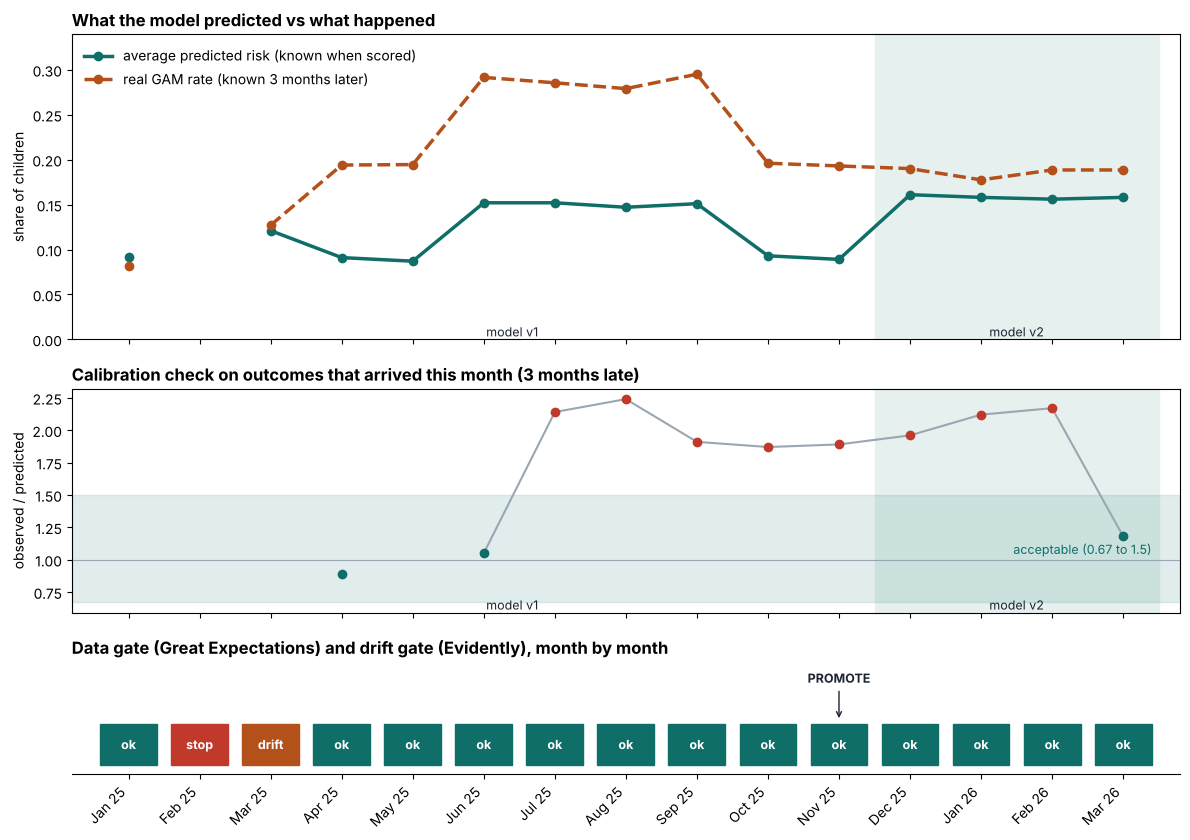

In [2]:
TEAL, ORANGE, RED, GREY, INK = "#0f6e68", "#b4501a", "#c0392b", "#9aa6b2", "#1b2430"
x = np.arange(len(log))
fig, (a1, a2, a3) = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True, gridspec_kw={"height_ratios": [3, 2.2, 1.1]})

# 1. what the model predicted vs what really happened
a1.plot(x, log["mean_risk"], color=TEAL, lw=2.5, marker="o", label="average predicted risk (known when scored)")
a1.plot(x, log["observed"], color=ORANGE, lw=2.5, marker="o", ls="--", label="real GAM rate (known 3 months later)")
a1.set(ylabel="share of children", ylim=(0, max(0.30, log["observed"].max() * 1.15)))
a1.legend(frameon=False, loc="upper left")
a1.set_title("What the model predicted vs what happened", loc="left", fontweight="bold")

# 2. the check that eventually notices: observed / predicted, for the month whose outcomes just arrived
a2.axhspan(0.67, 1.5, color=TEAL, alpha=0.12)
a2.text(len(log) - 0.6, 1.08, "acceptable (0.67 to 1.5)", ha="right", va="center", color=TEAL, fontsize=9)
ok = log["obs/pred"].between(0.67, 1.5)
a2.plot(x, log["obs/pred"], color=GREY, lw=1.5)
a2.scatter(x[ok], log["obs/pred"][ok], color=TEAL, zorder=3)
a2.scatter(x[~ok & log["obs/pred"].notna()], log["obs/pred"][~ok & log["obs/pred"].notna()], color=RED, zorder=3)
a2.axhline(1, color=GREY, lw=0.8)
a2.set(ylabel="observed / predicted")
a2.set_title("Calibration check on outcomes that arrived this month (3 months late)", loc="left", fontweight="bold")

# 3. what the pipeline did each month
state = np.where(log["status"].str.startswith("BLOCKED"), "BLOCKED", np.where(log["drift_gate"].str.startswith("ALERT"), "ALERT", "ok"))
colour = {"ok": TEAL, "ALERT": ORANGE, "BLOCKED": RED}
for i, s in enumerate(state):
    a3.add_patch(plt.Rectangle((i - 0.4, 0.15), 0.8, 0.7, color=colour[s]))
    a3.text(i, 0.5, {"ok": "ok", "ALERT": "drift", "BLOCKED": "stop"}[s], ha="center", va="center", color="white", fontsize=9, fontweight="bold")
promoted = log.index[log["retrain"].fillna("").str.startswith("PROMOTE")]
for i in promoted:
    a3.annotate("PROMOTE", (i, 0.9), (i, 1.55), ha="center", fontsize=9, fontweight="bold", color=INK, arrowprops=dict(arrowstyle="->", color=INK))
a3.set(ylim=(0, 1.9), yticks=[]); a3.set_title("Data gate (Great Expectations) and drift gate (Evidently), month by month", loc="left", fontweight="bold")
for s in ("top", "right", "left"):
    a3.spines[s].set_visible(False)

# the model in service: shade the months scored by each version
v = log["model_version"].astype(str)
for ax in (a1, a2):
    for ver, shade in zip(v.unique(), ["#ffffff", "#f1eee6", "#e6f1ef"]):
        idx = np.where(v == ver)[0]
        if len(idx):
            ax.axvspan(idx.min() - 0.5, idx.max() + 0.5, color=shade, zorder=0)
            ax.text(idx.mean(), ax.get_ylim()[0], f"model {ver}", ha="center", va="bottom", fontsize=9, color=INK)
a3.set_xticks(x, log["when"], rotation=45, ha="right")
for ax in (a1, a2, a3):
    ax.margins(x=0.02)
plt.tight_layout()
plt.show()

### How to read it

1. **Left of April.** Predicted and real rates move together (the model is calibrated). The February box says *stop*: the data gate
   blocked a broken file, so nothing was scored. In March the drift gate fires (new regions), but nothing is wrong with the model yet.
2. **April on.** The real rate rises well above the predicted one (food distribution stopped), but **no input looks different**,
   so the drift gate stays quiet. Nothing can see it yet.
3. **July.** Outcomes for April arrive. Observed / predicted jumps outside the band: now it can be seen, three months late.
4. **August to October.** The alert continues, but the challenger models are still mostly trained on months from before the shift: *keep*.
5. **November.** A challenger trained on the post-shift months passes the written rule: **promote**. Seven months after the shift.
6. **After that.** The ratio returns to the band for months scored by the new model.

## The same thing as a table

In [3]:
show = log[["when", "scenario (hidden truth)", "status", "model_version", "drift_gate", "outcomes_for", "obs/pred", "auc", "retrain"]].copy()
show.columns = ["month", "hidden truth", "status", "model", "drift gate", "outcomes for", "obs/pred", "auc", "retrain decision"]
show["drift gate"] = show["drift gate"].str.slice(0, 40)
show["retrain decision"] = show["retrain decision"].fillna("").astype(str).str.slice(0, 46)

def paint(row):
    if row["status"].startswith("BLOCKED"):
        c = "#f6d5d0"
    elif str(row["retrain decision"]).startswith("PROMOTE"):
        c = "#cfe8e4"
    elif str(row["drift gate"]).startswith("ALERT"):
        c = "#f8e3d0"
    else:
        c = ""
    return [f"background-color: {c}"] * len(row)

(show.style.apply(paint, axis=1).format({"obs/pred": "{:.2f}", "auc": "{:.3f}"}, na_rep="")
     .hide(axis="index").set_properties(**{"font-size": "13px", "text-align": "left"}))

month,hidden truth,status,model,drift gate,outcomes for,obs/pred,auc,retrain decision
Jan 25,baseline,ok,v1,ok,"2024-10 (history, not scored by the pipeline)",,,
Feb 25,messy_export,BLOCKED by GX,,,,,,
Mar 25,new_regions,ok,v1,ALERT: Value drift for risk; Value drift,"2024-12 (history, not scored by the pipeline)",,,
Apr 25,concept_shift,ok,v1,ok,2025-01 (scored by v1),0.89,0.806,
May 25,concept_shift,ok,v1,ok,2025-02 (quarantined),,,
Jun 25,concept_shift,ok,v1,ok,2025-03 (scored by v1),1.05,0.782,
Jul 25,concept_shift,ok,v1,ok,2025-04 (scored by v1),2.14,0.820,keep (calibration not better)
Aug 25,concept_shift,ok,v1,ok,2025-05 (scored by v1),2.24,0.828,keep (calibration not better)
Sep 25,concept_shift,ok,v1,ok,2025-06 (scored by v1),1.91,0.815,keep (calibration not better)
Oct 25,concept_shift,ok,v1,ok,2025-07 (scored by v1),1.87,0.817,keep (calibration not better)
